<a href="https://colab.research.google.com/github/ronan-cunha/machine-learning-course/blob/main/Notebooks/aula_11_random_forest_classificacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml, load_diabetes
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

In [2]:
# ==============================================================================
# ETAPA 1: Carregar Dataset Real (Diabetes)
# ==============================================================================
# O dataset possui 442 observações e 10 variáveis preditoras clínicas:
# age (idade), sex (sexo), bmi (IMC), bp (pressão arterial média)
# s1 a s6 (seis medições do soro sanguíneo, ex: colesterol total, LDL, HDL, triglicérides, glicose)
# https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [13]:
# ==============================================================================
# ETAPA 2: Divisão entre Treino e Teste
# ==============================================================================
X = df.drop(columns=["target"])
y = df["target"]

# 1. Binarização do Target para Classificação
# - 1 se a progressão da doença estiver acima da mediana (alto risco).
# - 0 se estiver abaixo da mediana (baixo risco).
median_target = y.mean()
y_class = (y > median_target).astype(int)

feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y_class, test_size=0.20, random_state=42
)

print(f"Amostras de Treino: {X_train.shape[0]} | Amostras de Teste: {X_test.shape[0]}\n")

Amostras de Treino: 353 | Amostras de Teste: 89



In [14]:
pd.concat([y_train.describe(), y_test.describe()], axis=1, keys=['Treino', 'Teste'])

,Treino,Teste
count,353.000000,89.000000
mean,0.441926,0.438202
std,0.497321,0.498978
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,1.000000,1.000000
max,1.000000,1.000000


In [15]:
# ==============================================================================
# ETAPA 3: Instanciar e Treinar o Modelo Random Forest com Índice de Gini
# ==============================================================================
rf_gini = RandomForestClassifier(
    n_estimators=500,
    criterion='gini',
    max_features=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Ajustando os modelos
rf_gini.fit(X_train, y_train)

# Predições
y_pred_gini = rf_gini.predict(X_test)

# Avaliação
acc_gini = accuracy_score(y_test, y_pred_gini)

In [16]:
# Erro de Classificação final (Misclassification Error)
err_gini = 1.0 - acc_gini

print("--- Comparação de Critérios de Divisão ---")
print(f"Gini - Acurácia: {acc_gini:.4f} | Erro de Classificação: {err_gini:.4f}")

--- Comparação de Critérios de Divisão ---
Gini - Acurácia: 0.7416 | Erro de Classificação: 0.2584


In [17]:
# ==============================================================================
# ETAPA 4: Instanciar e Treinar o Modelo Random Forest com Entropia
# ==============================================================================
rf_entropy = RandomForestClassifier(
    n_estimators=500,
    criterion='entropy',
    max_features=5,
    min_samples_leaf=2,
    random_state=44,
    n_jobs=-1
)

# Ajustando os modelos
rf_entropy.fit(X_train, y_train)

# Predições
y_pred_entropy = rf_entropy.predict(X_test)

# Avaliação
acc_entropy = accuracy_score(y_test, y_pred_entropy)

In [ ]:
# ==============================================================================
# ETAPA 5: Instanciar e Treinar o Modelo Random Forest com Erro de classificação
# ==============================================================================
# Como o scikit-learn não possui o Erro de Classificação implementado nativamente
# no parâmetro 'criterion', implementamos uma função para calcularmos esse critério
# manualmente.

def erro_classificacao(y_subset):
    """Calcula o Erro de Classificação para um subconjunto de classes."""
    if len(y_subset) == 0:
        return 0.0

    # Encontra a proporção da classe mais frequente (p_max)
    contagem = pd.Series(y_subset).value_counts()
    proporcoes = contagem / len(y_subset)
    p_max = proporcoes.max()

    # Erro de Classificação = 1 - max(p_i)
    return 1.0 - p_max

# Calculando o erro de classificação inicial do conjunto de treino
erro_inicial = erro_classificacao(y_train)
print(f"Erro de Classificação Inicial (Sem divisões): {erro_inicial:.4f}")

# Exemplo de simulação de split pela variável 'bmi' (acima ou abaixo de 0.01)
split_condicao = X_train['bmi'] > 0.01
y_esquerdo = y_train[split_condicao]
y_direito = y_train[~split_condicao]

erro_esq = erro_classificacao(y_esquerdo)
erro_dir = erro_classificacao(y_direito)

# Erro ponderado pós-split
peso_esq = len(y_esquerdo) / len(y_train)
peso_dir = len(y_direito) / len(y_train)
erro_ponderado = (peso_esq * erro_esq) + (peso_dir * erro_dir)

print(f"Erro no nó Esquerdo: {erro_esq:.4f} (proporção: {peso_esq:.2f})")
print(f"Erro no nó Direito: {erro_dir:.4f} (proporção: {peso_dir:.2f})")
print(f"Erro de Classificação Ponderado após Divisão: {erro_ponderado:.4f}")
print(f"Ganho de Informação (Redução do Erro): {erro_inicial - erro_ponderado:.4f}")

In [18]:

# Erro de Classificação final (Misclassification Error)
err_gini = 1.0 - acc_gini
err_entropy = 1.0 - acc_entropy

print("--- Comparação de Critérios de Divisão ---")
print(f"Gini    - Acurácia: {acc_gini:.4f} | Erro de Classificação: {err_gini:.4f}")
print(f"Entropy - Acurácia: {acc_entropy:.4f} | Erro de Classificação: {err_entropy:.4f}")

--- Comparação de Critérios de Divisão ---
Gini    - Acurácia: 0.7416 | Erro de Classificação: 0.2584
Entropy - Acurácia: 0.7528 | Erro de Classificação: 0.2472


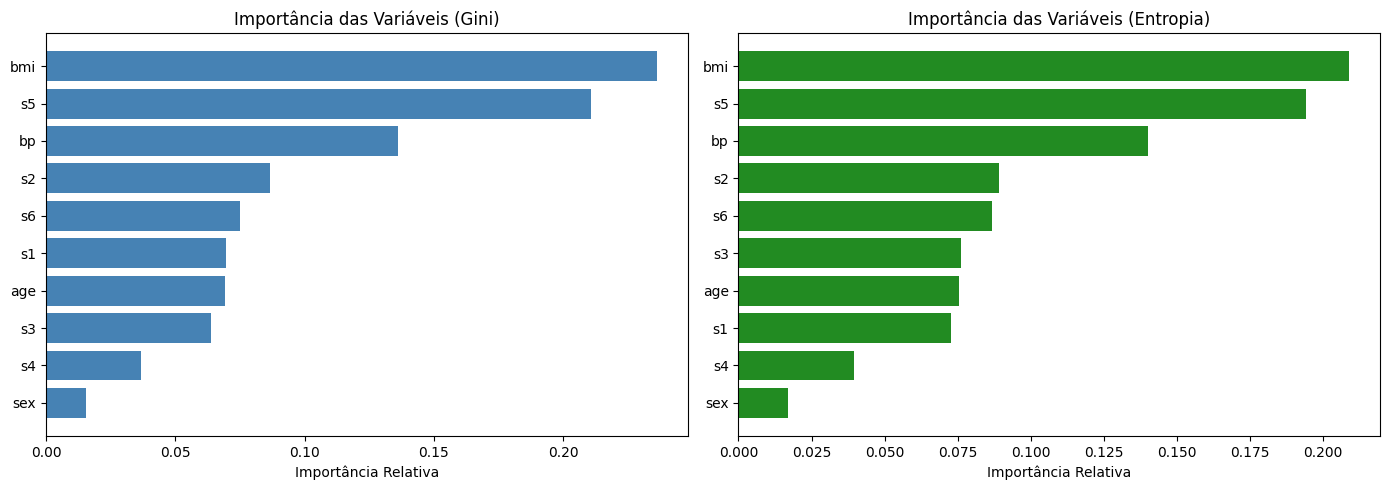

In [19]:
# Visualização da diferença de importância de variáveis entre Gini e Entropia
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gini
importances_gini = pd.DataFrame({
    'Feature': feature_names,
    'Importancia': rf_gini.feature_importances_
}).sort_values(by='Importancia', ascending=True)

axes[0].barh(importances_gini['Feature'], importances_gini['Importancia'], color='steelblue')
axes[0].set_title('Importância das Variáveis (Gini)')
axes[0].set_xlabel('Importância Relativa')

# Entropia
importances_entropy = pd.DataFrame({
    'Feature': feature_names,
    'Importancia': rf_entropy.feature_importances_
}).sort_values(by='Importancia', ascending=True)

axes[1].barh(importances_entropy['Feature'], importances_entropy['Importancia'], color='forestgreen')
axes[1].set_title('Importância das Variáveis (Entropia)')
axes[1].set_xlabel('Importância Relativa')

plt.tight_layout()
plt.show()